In [ ]:
from collections import defaultdict
from tqdm.notebook import tqdm

import numpy

from scipy.stats import gaussian_kde
from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    r2_score,
)
import torch

from robat.models import RoBaTForNextCyclePrediction
from robat.datasets.ds_preprocess import (
    ds_preprocess_for_eval,
)

from accelerate import Accelerator

from matplotlib import pyplot

In [ ]:
model = RoBaTForNextCyclePrediction.from_pretrained(
    "Junhyeong86/battery-health-prediction-model",
    subfolder="next-cycle-prediction"
)

In [3]:
ds = ds_preprocess_for_eval(
    ds_name="Junhyeong86/battery-health-prediction",
    model_purpose="next_cycle_prediction",
    random_time_len=model.config.random_time_len,
    split_cycle_len=256,
)

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/1 [00:00<?, ? examples/s]

... (164 outputs left out)

Casting the dataset:   0%|          | 0/8 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/10 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9 [00:00<?, ? examples/s]

Casting the dataset:   0%|          | 0/9 [00:00<?, ? examples/s]

In [4]:
accelerator = Accelerator()
model = accelerator.prepare(model)
model.eval()
progress_bar = tqdm(total=len(ds), desc="Evaluating")
overall_label_and_pred = defaultdict(lambda: defaultdict(list))
for cell_id, data in ds.items():
    ref = cell_id.split("/")[0]
    progress_bar.set_postfix({"processing cell id": cell_id})
    inp = {
        "first_discharge_capacity": data["first_discharge_capacity"],
        "state_of_health": data["state_of_health"],
        "time": data["time"],
        "voltage_per_time": data["voltage_per_time"],
        "current_per_time": data["current_per_time"],
        "mask": data["mask"],
        "label_discharge_capacity": data["label_discharge_capacity"],
        "label_state_of_health": data["label_state_of_health"],
    }
    inp = {k: v.to(accelerator.device) for k, v in inp.items()}
    with torch.no_grad():
        pred = model(**inp)
    mask = data["label_discharge_capacity"] == model.config.padding_value
    pred_discharge_capacity = (
        pred.discharge_capacity[~mask]
        .detach()
        .cpu()
        .numpy()
    )
    label_discharge_capacity = (
        data["label_discharge_capacity"][~mask]
        .detach()
        .cpu()
        .numpy()
    )
    overall_label_and_pred[ref]["cell_id"].append(cell_id)
    overall_label_and_pred[ref]["pred_discharge_capacity"].append(pred_discharge_capacity)
    overall_label_and_pred[ref]["label_discharge_capacity"].append(label_discharge_capacity)
    progress_bar.update(1)
progress_bar.close()

Evaluating:   0%|          | 0/58 [00:00<?, ?it/s]

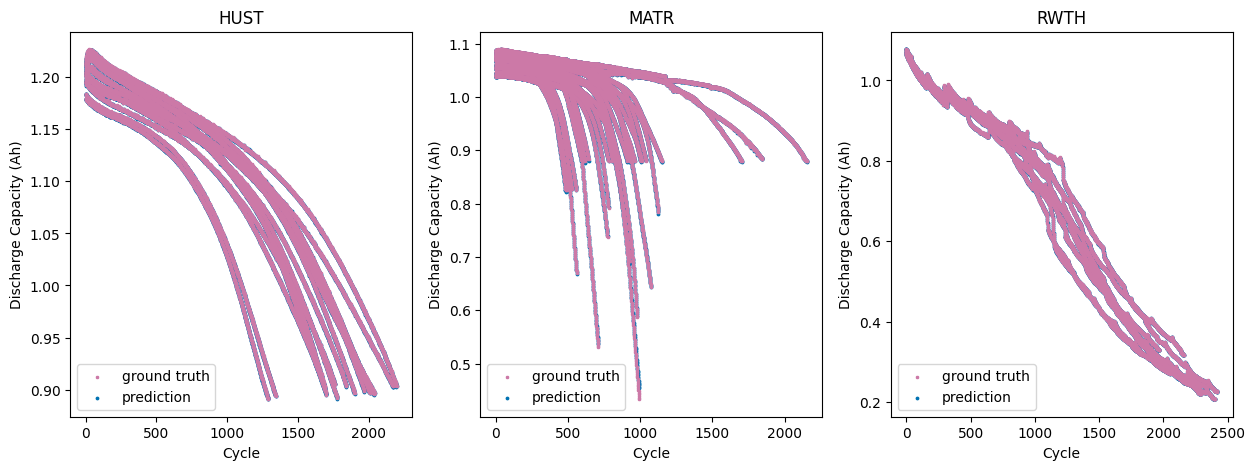

In [ ]:
fig, axes = pyplot.subplots(1, len(overall_label_and_pred), figsize=(15, 5))

for ax, (ref, data) in zip(axes, overall_label_and_pred.items()):
    ax.set_title(ref)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Discharge Capacity (Ah)")

    ref_iterator = zip(
        data["pred_discharge_capacity"],
        data["label_discharge_capacity"],
    )
    for pred, label in ref_iterator:
        cycle = numpy.arange(len(pred))
        # ax.plot(cycle, label, label="ground truth", c="#CC79A7", linestyle="--", zorder=2)
        ax.scatter(cycle, label, label="ground truth", c="#CC79A7", zorder=2, marker="o", s=3)
        ax.scatter(cycle, pred, label="prediction", c="#0072B2", zorder=1, marker="o", s=3)

    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc="lower left")

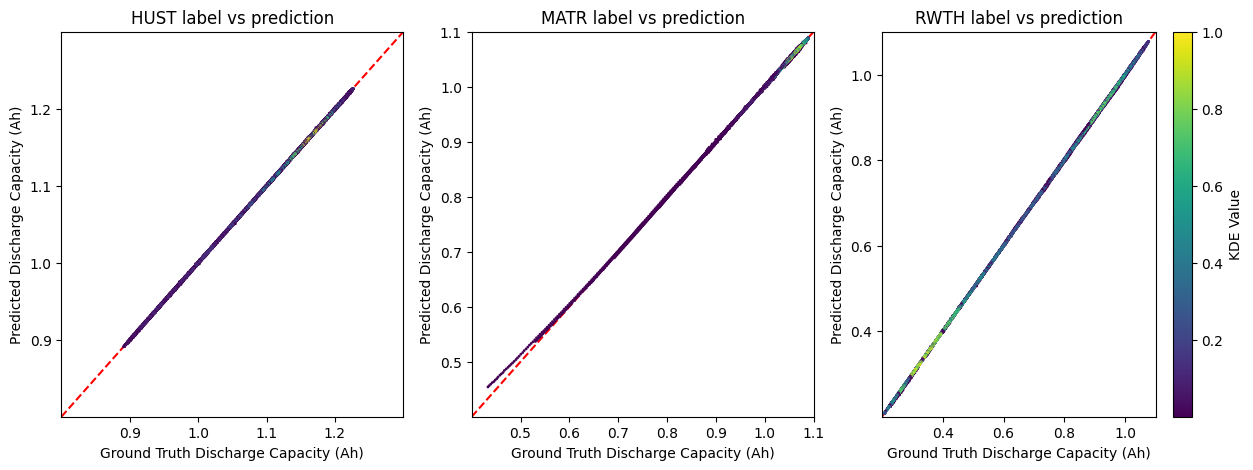

In [6]:
get_xrange = lambda x: (
    numpy.floor(x.min() * 10) / 10,
    numpy.ceil(x.max() * 10) / 10
)

fig, axes = pyplot.subplots(1, len(overall_label_and_pred), figsize=(15, 5))

for ax, (ref, data) in zip(axes, overall_label_and_pred.items()):
    ax.set_title(ref)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Discharge Capacity (Ah)")

    pred = numpy.hstack(data["pred_discharge_capacity"])
    label = numpy.hstack(data["label_discharge_capacity"])
    label_and_pred = numpy.vstack((label, pred))
    kde = gaussian_kde(label_and_pred)
    kde_values = kde(label_and_pred)
    kde_values = kde_values / kde_values.max()  # Normalize KDE values for better visualization
    sc = ax.scatter(
        label_and_pred[0],
        label_and_pred[1],
        c=kde_values,
        cmap="viridis",
        s=1,
        zorder=2,
    )
    xrange = get_xrange(label_and_pred[0])
    yrange = get_xrange(label_and_pred[1])
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.plot(
        xrange,
        xrange,
        c="red",
        linestyle="--",
        label="y=x",
        zorder=1,
    )
    ax.set_title(f"{ref} label vs prediction")
    ax.set_xlabel("Ground Truth Discharge Capacity (Ah)")
    ax.set_ylabel("Predicted Discharge Capacity (Ah)")
fig.colorbar(sc, ax=ax, label="KDE Value")
pyplot.show()

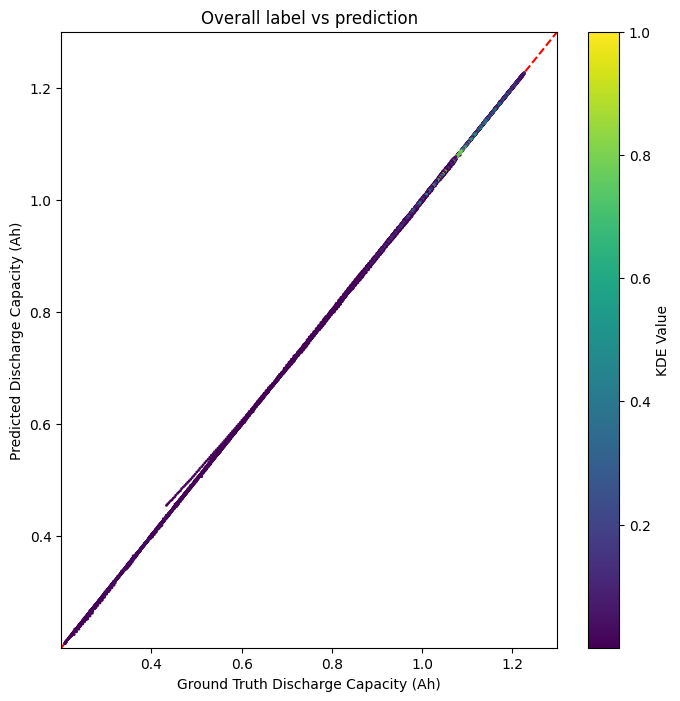

In [7]:
fig, ax = pyplot.subplots(figsize=(8, 8))

pred = numpy.hstack([
    numpy.hstack(data["pred_discharge_capacity"])
    for data in overall_label_and_pred.values()
])
label = numpy.hstack([
    numpy.hstack(data["label_discharge_capacity"])
    for data in overall_label_and_pred.values()
])
label_and_pred = numpy.vstack((label, pred))
kde = gaussian_kde(label_and_pred)
kde_values = kde(label_and_pred)
kde_values = kde_values / kde_values.max()  # Normalize KDE values for better visualization

sc = ax.scatter(
    label_and_pred[0],
    label_and_pred[1],
    c=kde_values,
    cmap="viridis",
    s=1,
    zorder=2,
)
xrange = get_xrange(label_and_pred[0])
yrange = get_xrange(label_and_pred[1])
ax.set_xlim(xrange)
ax.set_ylim(yrange)
ax.plot(
    xrange,
    xrange,
    c="red",
    linestyle="--",
    label="y=x",
    zorder=1,
)
ax.set_title("Overall label vs prediction")
ax.set_xlabel("Ground Truth Discharge Capacity (Ah)")
ax.set_ylabel("Predicted Discharge Capacity (Ah)")

fig.colorbar(sc, ax=ax, label="KDE Value")
pyplot.show()

In [17]:
rmse = root_mean_squared_error(label, pred) * 1e3  # Convert to mAh
mae = mean_absolute_error(label, pred) * 1e3  # Convert to mAh
r2 = r2_score(label, pred) * 100  # Convert to percentage
print(
    f"RMSE: {rmse:.4f} mAh\n"
    f"MAE: {mae:.4f} mAh\n"
    f"R2: {r2:.4f} %"
)

RMSE: 0.8950 mAh
MAE: 0.5488 mAh
R2: 99.9984 %
